# 05. Random Forest: tinh chỉnh siêu tham số và đánh giá trên validation (T11)

**Mục tiêu:** chọn siêu tham số cho Random Forest bằng kiểm định chéo theo thời gian trên tập train, đánh giá mô hình tốt nhất trên tập validation, và xem mô hình dựa vào những đặc trưng nào.

**Sản phẩm:**

- `models/random_forest_best_params.json`: siêu tham số tốt nhất (TN2 sẽ dùng lại).
- Hai dòng `RandomForest` (`cv`, `validation`) trong `reports/results/results.csv`.
- Hình `reports/figures/random_forest_tuning.png`, `random_forest_confusion_matrix.png`, `random_forest_feature_importance.png`.

**Nguyên tắc (theo `docs/decisions.md`, Mục 5.2):** tinh chỉnh bằng `time_series_cv` trên train (5 fold, PR-AUC); validation chỉ dùng để đánh giá mô hình đã chọn; **không dùng tập test**.

## 0. Chuẩn bị

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook runs from the project root or from notebooks/
ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

RESULTS_PATH = ROOT / "reports" / "results" / "results.csv"
PARAMS_PATH = ROOT / "models" / "random_forest_best_params.json"
PARAMS_PATH.parent.mkdir(parents=True, exist_ok=True)

import itertools
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay

from src.config import CLEAN_CATEGORICAL_FEATURES, RANDOM_STATE, TARGET_COLUMN
from src.data import load_raw
from src.eda import save_figure
from src.evaluate import RESULT_COLUMNS, append_result, evaluate_classification, time_series_cv
from src.features import ENGINEERED_CATEGORICAL_FEATURES, ENGINEERED_NUMERIC_FEATURES, add_features
from src.preprocess import build_model_pipeline, clean_data
from src.split import temporal_split

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.4f}".format)

TARGET = TARGET_COLUMN
MODEL_NAME = "RandomForest"

## 1. Dữ liệu và bộ đặc trưng

Luồng xử lý giống `03_baseline.ipynb` và `04_gradient_boosting.ipynb`: `load_raw` → `clean_data` → `add_features` → `temporal_split`. Bộ đặc trưng gồm 22 cột sạch (M1) và `arrival_weekday` (T08). Danh sách 13 biến số lấy giống hệt notebook 03 và 04, vì `src/config.py` mới có danh sách biến phân loại.

In [2]:
df = add_features(clean_data(load_raw()))

CLEAN_NUMERIC_FEATURES = [
    "lead_time", "arrival_date_week_number", "arrival_date_day_of_month",
    "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
    "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
    "adr", "total_of_special_requests",
]
NUMERIC_FEATURES = CLEAN_NUMERIC_FEATURES + list(ENGINEERED_NUMERIC_FEATURES)
CATEGORICAL_FEATURES = list(CLEAN_CATEGORICAL_FEATURES) + list(ENGINEERED_CATEGORICAL_FEATURES)
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

# Columns that must never reach the model (docs/decisions.md, sections 3.1 and 3.4)
FORBIDDEN = {
    TARGET, "reservation_status", "reservation_status_date", "arrival_date",
    "arrival_date_year", "assigned_room_type", "booking_changes", "days_in_waiting_list",
    "deposit_type", "country", "required_car_parking_spaces",
}
assert len(FEATURES) == 23 and len(set(FEATURES)) == 23
assert not (set(FEATURES) & FORBIDDEN), "forbidden column in the feature list"
assert set(FEATURES) <= set(df.columns)

train, valid, test = temporal_split(df, train_end="2017-01-01", valid_end="2017-07-01", date_col="arrival_date")
X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]

display(pd.DataFrame(
    {"rows": [len(train), len(valid), len(test)],
     "cancel_rate": [train[TARGET].mean(), valid[TARGET].mean(), test[TARGET].mean()]},
    index=["train", "validation", "test (held out, not used)"],
))
print(f"{len(FEATURES)} features: {len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL_FEATURES)} categorical")

,rows,cancel_rate
train,78586,0.3622
validation,30386,0.3928
"test (held out, not used)",10233,0.3712


23 features: 13 numeric, 10 categorical


## 2. Tinh chỉnh siêu tham số

Random Forest huấn luyện nhiều cây quyết định, mỗi cây trên một mẫu bootstrap của dữ liệu và chỉ xét một phần ngẫu nhiên các cột ở mỗi lần chia nhánh; dự đoán là trung bình xác suất của các cây. Lưới thử 36 cấu hình (300 cây, `random_state=42`):

| Siêu tham số | Giá trị thử | Vai trò |
|---|---|---|
| `min_samples_leaf` | 1, 5, 20 | Số booking tối thiểu ở mỗi lá: lá lớn hơn làm cây đơn giản hơn, giảm việc học thuộc các khối booking trùng nhau |
| `max_features` | `"sqrt"`, 0,3, 0,5 | Tỉ lệ cột xét ở mỗi lần chia: nhỏ thì các cây khác nhau nhiều hơn, lớn thì mỗi cây mạnh hơn |
| `max_depth` | None, 20 | Giới hạn độ sâu của cây, một cách khác để chống overfit |
| `class_weight` | None, `"balanced_subsample"` | Tăng trọng số lớp hủy (36% train) trong từng mẫu bootstrap |

Mỗi cấu hình được đánh giá bằng `time_series_cv` (5 fold, PR-AUC) trên train; chọn cấu hình có PR-AUC trung bình cao nhất. `n_estimators` không đưa vào lưới vì thêm cây chỉ làm kết quả ổn định hơn chứ không gây overfit; Mục 2.1 kiểm tra 300 cây đã đủ.

In [3]:
BASE_PARAMS = {"n_estimators": 300, "n_jobs": -1, "random_state": RANDOM_STATE}
GRID = {
    "min_samples_leaf": [1, 5, 20],
    "max_features": ["sqrt", 0.3, 0.5],
    "max_depth": [None, 20],
    "class_weight": [None, "balanced_subsample"],
}


def make_pipeline(params: dict):
    return build_model_pipeline(
        X_train, RandomForestClassifier(**params),
        numeric_features=NUMERIC_FEATURES, categorical_features=CATEGORICAL_FEATURES,
        scale_numeric=False,
    )


rows, fold_scores = [], {}
for values in itertools.product(*GRID.values()):
    candidate = dict(zip(GRID, values))
    scores = time_series_cv(make_pipeline({**BASE_PARAMS, **candidate}), X_train, y_train,
                            n_splits=5, scoring="average_precision")
    key = json.dumps(candidate)
    fold_scores[key] = scores["score"].to_numpy()
    # Keep hyperparameter values as text so None and 20 are not turned into NaN/20.0
    rows.append({**{k: str(v) for k, v in candidate.items()}, "pr_auc_mean": scores["score"].mean(),
                 "pr_auc_std": scores["score"].std(ddof=1), "key": key})

cv_results = (pd.DataFrame(rows).sort_values("pr_auc_mean", ascending=False)
              .reset_index(drop=True))
cv_results.index += 1
display(cv_results.drop(columns="key").head(10))

# Mean and best CV PR-AUC for each value of each hyperparameter
by_value = pd.concat(
    {name: cv_results.groupby(name)["pr_auc_mean"].agg(["mean", "max"]).reindex([str(v) for v in values])
     for name, values in GRID.items()},
    names=["hyperparameter", "value"],
)
display(by_value)

best = cv_results.iloc[0]
best_candidate = json.loads(best["key"])
best_params = {**BASE_PARAMS, **best_candidate}
print("Best configuration:", best_candidate)
print(f"CV PR-AUC: {best['pr_auc_mean']:.4f} ± {best['pr_auc_std']:.4f}")
print("Per-fold PR-AUC:", np.round(fold_scores[best["key"]], 4))

,min_samples_leaf,max_features,max_depth,class_weight,pr_auc_mean,pr_auc_std
1,20,sqrt,20,balanced_subsample,0.7991,0.0140
2,20,sqrt,None,balanced_subsample,0.7989,0.0128
3,20,sqrt,None,None,0.7984,0.0124
4,20,sqrt,20,None,0.7983,0.0140
5,5,sqrt,20,None,0.7967,0.0115
6,5,sqrt,20,balanced_subsample,0.7960,0.0142
7,5,sqrt,None,None,0.7948,0.0139
8,5,sqrt,None,balanced_subsample,0.7943,0.0128
9,20,0.3,None,balanced_subsample,0.7940,0.0110
10,20,0.3,20,balanced_subsample,0.7939,0.0121


mean    max
hyperparameter   value                           
min_samples_leaf 1                  0.7696 0.7850
                 5                  0.7865 0.7967
                 20                 0.7927 0.7991
max_features     sqrt               0.7906 0.7991
                 0.3                0.7839 0.7940
                 0.5                0.7743 0.7873
max_depth        None               0.7818 0.7989
                 20                 0.7840 0.7991
class_weight     None               0.7830 0.7984
                 balanced_subsample 0.7829 0.7991

Best configuration: {'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 20, 'class_weight': 'balanced_subsample'}
CV PR-AUC: 0.7991 ± 0.0140
Per-fold PR-AUC: [0.7859 0.8201 0.8031 0.7867 0.7997]


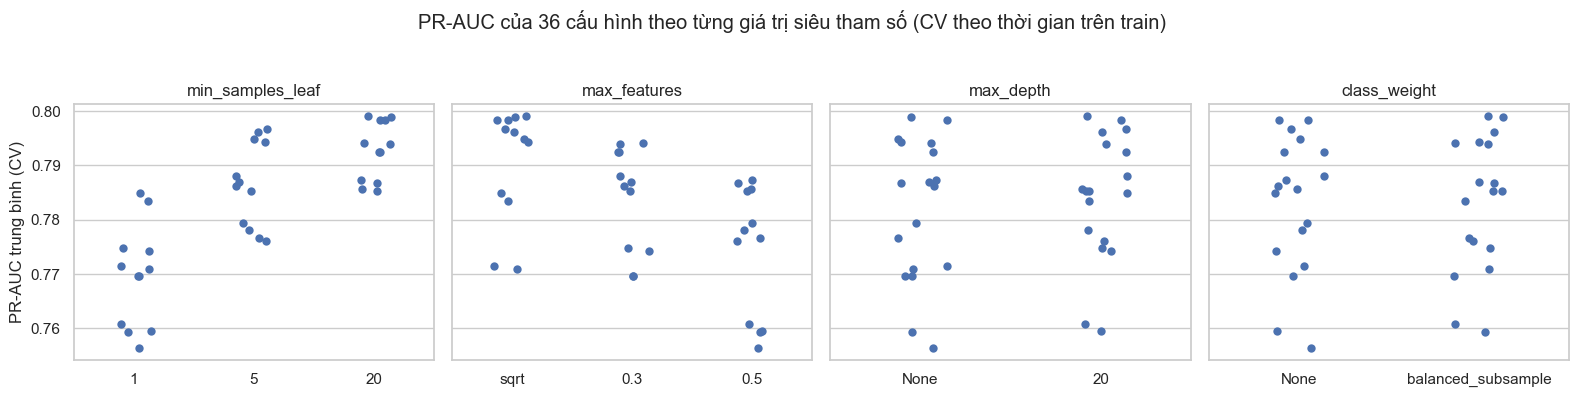

In [4]:
# How each hyperparameter value performs across all other settings
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, name in zip(axes, GRID):
    order = [str(v) for v in GRID[name]]
    sns.stripplot(data=cv_results, x=name, y="pr_auc_mean", order=order, ax=ax, size=6, jitter=0.15)
    ax.set_title(name)
    ax.set_xlabel("")
axes[0].set_ylabel("PR-AUC trung bình (CV)")
fig.suptitle("PR-AUC của 36 cấu hình theo từng giá trị siêu tham số (CV theo thời gian trên train)", y=1.04)
fig.tight_layout()
save_figure(fig, "random_forest_tuning")
plt.show()

**Nhận xét:**

- **Cấu hình tốt nhất:** `min_samples_leaf`=20, `max_features`="sqrt", `max_depth`=20, `class_weight`="balanced_subsample". CV PR-AUC 0,799 ± 0,014 (từng fold: 0,786; 0,820; 0,803; 0,787; 0,800), cao hơn Logistic Regression của T09 (0,752 ± 0,012).
- **Hai tham số quyết định kết quả là `min_samples_leaf` và `max_features`:**
  - Lá càng lớn càng tốt: PR-AUC trung bình 0,770 (lá 1), 0,787 (lá 5), 0,793 (lá 20). Lá 1 là mặc định của sklearn: cây mọc đến khi mỗi lá chỉ còn rất ít booking, nên học thuộc chi tiết của train, kể cả các khối booking đoàn giống hệt nhau, và dự đoán kém hơn ở giai đoạn sau.
  - Xét ít cột ở mỗi lần chia tốt hơn: `"sqrt"` (khoảng 8 trong 75 cột sau mã hóa) đạt trung bình 0,791, so với 0,784 (0,3) và 0,774 (0,5). Khi mỗi lần chia chỉ xét ít cột, các cây khác nhau nhiều hơn, nên lấy trung bình cả rừng giảm được nhiều phương sai hơn.
- **`max_depth` và `class_weight` gần như không ảnh hưởng:** trung bình chênh nhau dưới 0,003 (`max_depth`: 0,782 so với 0,784; `class_weight`: 0,783 so với 0,783). Với `class_weight`, điều này đúng như dự đoán: PR-AUC chỉ phụ thuộc thứ hạng của xác suất, còn trọng số lớp chủ yếu đẩy xác suất lên hoặc xuống, ảnh hưởng tới F1 ở một ngưỡng cố định (việc của TN3).
- **4 cấu hình đứng đầu chênh nhau dưới 0,001**, nhỏ hơn nhiều so với độ lệch chuẩn giữa các fold (khoảng 0,013), nên thực chất là ngang nhau. Cấu hình đứng đầu được chọn theo quy tắc đã đặt (PR-AUC trung bình cao nhất).

### 2.1. Hai kiểm tra bổ sung

- **300 cây đã đủ chưa?** Thêm cây không làm mô hình overfit, chỉ làm trung bình của rừng ổn định hơn và tốn thời gian hơn. Chạy lại cấu hình tốt nhất với 500 cây.
- **Giá trị tốt nhất của `min_samples_leaf` (20) nằm ở biên lưới.** Thử thêm 50 và 100, giữ nguyên các tham số khác, để chắc chắn không bỏ sót vùng tốt hơn.

In [5]:
scores_500 = time_series_cv(make_pipeline({**best_params, "n_estimators": 500}), X_train, y_train,
                            n_splits=5, scoring="average_precision")
print(f"300 trees: {best['pr_auc_mean']:.4f} ± {best['pr_auc_std']:.4f}")
print(f"500 trees: {scores_500['score'].mean():.4f} ± {scores_500['score'].std(ddof=1):.4f}")

for leaf in [50, 100]:
    scores_leaf = time_series_cv(make_pipeline({**best_params, "min_samples_leaf": leaf}), X_train, y_train,
                                 n_splits=5, scoring="average_precision")
    print(f"min_samples_leaf={leaf}: {scores_leaf['score'].mean():.4f} ± {scores_leaf['score'].std(ddof=1):.4f}")

PARAMS_PATH.write_text(json.dumps(best_params, indent=2, sort_keys=True) + "\n", encoding="utf-8")
print("Saved best parameters to", PARAMS_PATH.relative_to(ROOT).as_posix())

300 trees: 0.7991 ± 0.0140
500 trees: 0.8001 ± 0.0139


min_samples_leaf=50: 0.7985 ± 0.0142


min_samples_leaf=100: 0.7928 ± 0.0162
Saved best parameters to models/random_forest_best_params.json


**Nhận xét:**

- **500 cây** đạt 0,800 ± 0,014, chỉ hơn 300 cây 0,001, nhỏ hơn nhiều so với độ lệch chuẩn. Giữ 300 cây để chạy nhanh hơn.
- **`min_samples_leaf` lớn hơn 20 không tốt hơn:** 50 đạt 0,799 ± 0,014 (gần như bằng 20), 100 giảm còn 0,793 ± 0,016. Vùng tốt nhất nằm quanh 20–50, nên giữ 20 và không cần mở rộng lưới.

## 3. Đánh giá trên validation

Mô hình với cấu hình tốt nhất được huấn luyện lại trên toàn bộ train rồi đánh giá trên validation (01–06/2017) ở ngưỡng 0,5. Ngưỡng theo chi phí là việc của TN3. Bảng dưới so với các mô hình đã có trong `results.csv`.

In [6]:
best_pipeline = make_pipeline(best_params).fit(X_train, y_train)
y_score = best_pipeline.predict_proba(X_valid)[:, 1]
y_pred = (y_score >= 0.5).astype(int)
validation_metrics = evaluate_classification(y_valid, y_pred, y_score)

existing = pd.read_csv(RESULTS_PATH)
others = existing[
    existing["experiment"].eq("main") & existing["feature_set"].eq("clean")
    & existing["split"].eq("temporal") & existing["model_name"].ne(MODEL_NAME)
]
cv_part = others[others["eval_set"].eq("cv")].set_index("model_name")[["average_precision", "average_precision_std"]]
valid_part = others[others["eval_set"].eq("validation")].set_index("model_name")[
    ["average_precision", "f1", "roc_auc", "precision", "recall"]]
comparison = cv_part.rename(columns={"average_precision": "cv_pr_auc", "average_precision_std": "cv_pr_auc_std"}).join(
    valid_part.rename(columns={"average_precision": "valid_pr_auc"}))
comparison.loc[MODEL_NAME] = pd.Series({
    "cv_pr_auc": best["pr_auc_mean"], "cv_pr_auc_std": best["pr_auc_std"],
    "valid_pr_auc": validation_metrics["average_precision"], "f1": validation_metrics["f1"],
    "roc_auc": validation_metrics["roc_auc"], "precision": validation_metrics["precision"],
    "recall": validation_metrics["recall"],
})
print(f"Validation: {len(valid):,} bookings, cancellation rate {y_valid.mean():.4f} (PR-AUC of a random model)")
display(comparison.sort_values("valid_pr_auc"))

Validation: 30,386 bookings, cancellation rate 0.3928 (PR-AUC of a random model)


,cv_pr_auc,cv_pr_auc_std,valid_pr_auc,f1,roc_auc,precision,recall
model_name,,,,,,,
DummyClassifier,0.3511,0.0362,0.3928,0.0000,0.5000,0.0000,0.0000
LogisticRegression,0.7524,0.0122,0.7862,0.6586,0.8224,0.7593,0.5814
RandomForest,0.7991,0.0140,0.7924,0.6615,0.8384,0.7717,0.5788
GradientBoosting,0.7730,0.0105,0.8055,0.6580,0.8425,0.7904,0.5636


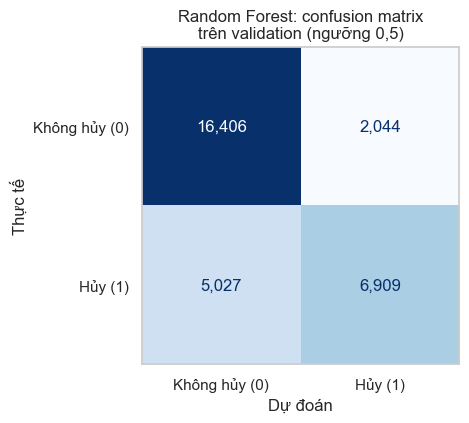

Canceled bookings caught: 6,909 of 11,936 (recall 57.9%)
Bookings flagged as canceled: 8,953, of which 2,044 were not canceled (precision 77.2%)


In [7]:
fig, ax = plt.subplots(figsize=(5, 4.4))
ConfusionMatrixDisplay.from_predictions(
    y_valid, y_pred, display_labels=["Không hủy (0)", "Hủy (1)"], cmap="Blues", values_format=",d",
    colorbar=False, ax=ax,
)
ax.set_xlabel("Dự đoán")
ax.set_ylabel("Thực tế")
ax.set_title("Random Forest: confusion matrix\ntrên validation (ngưỡng 0,5)")
ax.grid(False)
fig.tight_layout()
save_figure(fig, "random_forest_confusion_matrix")
plt.show()

tn, fp, fn, tp = (int(validation_metrics[k]) for k in ["TN", "FP", "FN", "TP"])
print(f"Canceled bookings caught: {tp:,} of {tp + fn:,} (recall {tp / (tp + fn):.1%})")
print(f"Bookings flagged as canceled: {tp + fp:,}, of which {fp:,} were not canceled (precision {tp / (tp + fp):.1%})")

**Nhận xét:**

- **Trên validation (01–06/2017), Random Forest đạt PR-AUC 0,792** (mốc của mô hình ngẫu nhiên là 0,393), F1 0,662, ROC-AUC 0,838, Precision 0,772, Recall 0,579 ở ngưỡng 0,5.
- **So với các mô hình khác:**
  - Tốt hơn Logistic Regression (chưa tinh chỉnh, T09) ở mọi metric: PR-AUC 0,792 so với 0,786; ROC-AUC 0,838 so với 0,822.
  - Thấp hơn Gradient Boosting (T12) trên validation: PR-AUC 0,792 so với 0,806, ROC-AUC 0,838 so với 0,843. Random Forest chỉ nhỉnh hơn ở F1 (0,662 so với 0,658) và Recall (0,579 so với 0,564).
- **Thứ tự này ngược với CV** (Random Forest 0,799, Gradient Boosting 0,773). Có ba lý do có thể:
  1. Random Forest được chọn từ 36 cấu hình, Gradient Boosting từ 4. Chọn cấu hình có điểm CV cao nhất trong nhiều cấu hình thì điểm đó thường hơi lạc quan so với hiệu năng thật.
  2. Các fold CV nằm trong 2015–2016, còn validation là năm 2017, khi phân phối dữ liệu đã thay đổi.
  3. Các chênh lệch chỉ khoảng 0,01–0,03, cùng cỡ với độ lệch chuẩn giữa các fold.

  Theo M1, các mô hình được so sánh trên validation, nên hiện Gradient Boosting dẫn đầu. Kết luận cuối cùng còn chờ Logistic Regression được tinh chỉnh (T10).
- **Confusion matrix:**
  - Trong 11.936 booking hủy thật, mô hình bắt được 6.909 (Recall 57,9%) và bỏ sót 5.027.
  - Trong 8.953 booking bị gắn cờ hủy, 2.044 thực tế không hủy (Precision 77,2%).

  Ở ngưỡng 0,5, mô hình thận trọng: ưu tiên ít báo nhầm hơn là bắt hết các booking hủy. Chọn ngưỡng theo chi phí là việc của TN3.

## 4. Mô hình dựa vào những đặc trưng nào?

Hai cách đo được dùng:

- **Permutation importance trên validation** (cách chính): xáo trộn ngẫu nhiên giá trị của một cột rồi đo PR-AUC giảm bao nhiêu. Đo trên dữ liệu mô hình chưa thấy, và mỗi cột gốc chỉ có một con số kể cả khi đã mã hóa one-hot. 5 lần xáo trộn cho mỗi cột, `random_state=42`.
- **Impurity importance (MDI)**: mức giảm độ hỗn tạp Gini khi chia nhánh theo cột đó, cộng dồn các cột one-hot về cột gốc. Đo trên train nên thiên vị biến số liên tục và biến có nhiều mức; chỉ dùng để đối chiếu.

,pr_auc_drop_mean,pr_auc_drop_std,mdi
total_of_special_requests,0.1368,0.0034,0.1389
customer_type,0.0971,0.0021,0.0912
market_segment,0.0882,0.0018,0.0973
lead_time,0.0672,0.0012,0.1582
agent,0.0252,0.0016,0.0949
hotel,0.0105,0.0009,0.0286
distribution_channel,0.0092,0.0013,0.0356
reserved_room_type,0.0062,0.0004,0.0110
stays_in_week_nights,0.0040,0.0004,0.0214
previous_cancellations,0.0034,0.0004,0.1137


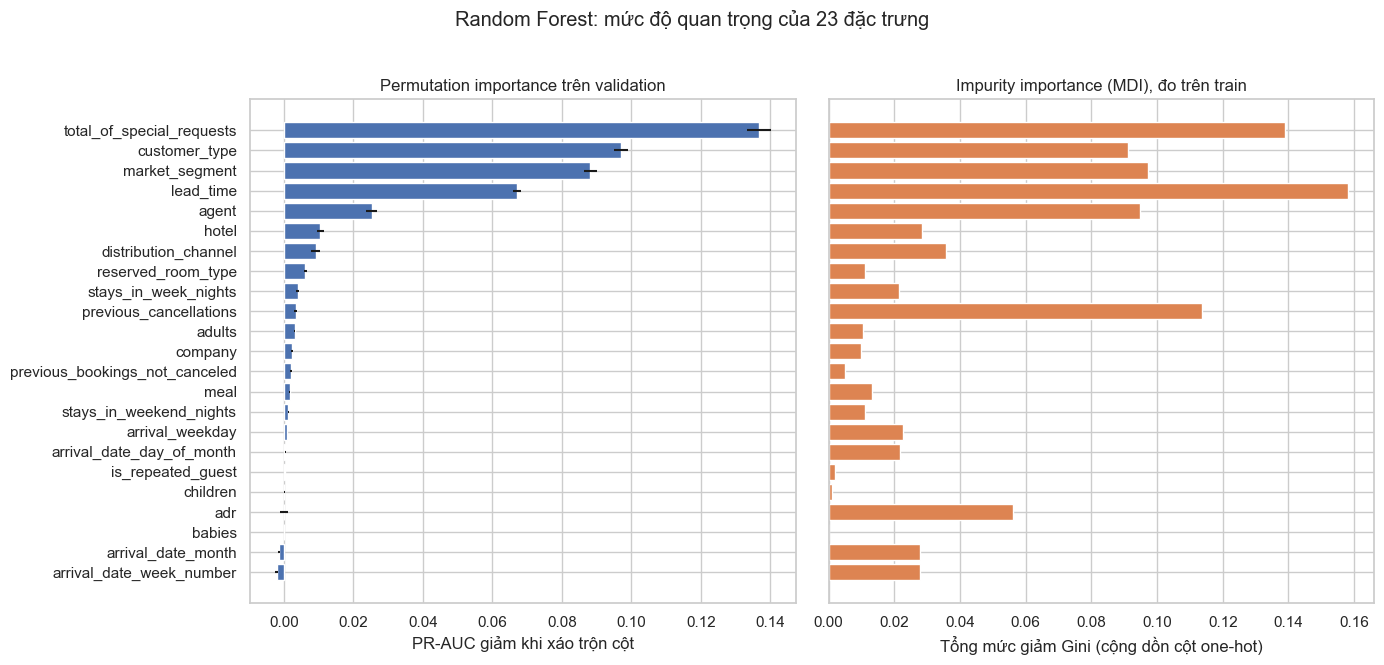

In [8]:
perm = permutation_importance(
    best_pipeline, X_valid, y_valid, scoring="average_precision",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=1,
)
perm_table = pd.DataFrame(
    {"pr_auc_drop_mean": perm.importances_mean, "pr_auc_drop_std": perm.importances_std}, index=FEATURES,
).sort_values("pr_auc_drop_mean", ascending=False)

# Impurity importance summed back to the original columns
encoded_names = best_pipeline.named_steps["preprocessor"].get_feature_names_out()
mdi = pd.Series(best_pipeline.named_steps["model"].feature_importances_, index=encoded_names)


def original_column(encoded: str) -> str:
    kind, name = encoded.split("__", 1)
    if kind == "numeric":
        return name
    return max((c for c in CATEGORICAL_FEATURES if name.startswith(c + "_")), key=len)


mdi_table = mdi.groupby(original_column).sum().rename("mdi")
importance = perm_table.join(mdi_table)
display(importance)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)
order = importance.index[::-1]
axes[0].barh(order, importance.loc[order, "pr_auc_drop_mean"],
             xerr=importance.loc[order, "pr_auc_drop_std"], color="#4C72B0")
axes[0].set_title("Permutation importance trên validation")
axes[0].set_xlabel("PR-AUC giảm khi xáo trộn cột")
axes[1].barh(order, importance.loc[order, "mdi"], color="#DD8452")
axes[1].set_title("Impurity importance (MDI), đo trên train")
axes[1].set_xlabel("Tổng mức giảm Gini (cộng dồn cột one-hot)")
fig.suptitle("Random Forest: mức độ quan trọng của 23 đặc trưng", y=1.02)
fig.tight_layout()
save_figure(fig, "random_forest_feature_importance")
plt.show()

**Nhận xét:**

- **Theo permutation importance trên validation, bốn đặc trưng chiếm phần lớn khả năng dự đoán:**
  - `total_of_special_requests`: xáo trộn làm PR-AUC giảm 0,137;
  - `customer_type`: 0,097;
  - `market_segment`: 0,088;
  - `lead_time`: 0,067.

  Tiếp theo là `agent` (0,025); các cột còn lại đều làm PR-AUC giảm dưới 0,011. Kết quả khớp với EDA: số yêu cầu đặc biệt và thời gian đặt trước là hai biến số tách lớp rõ nhất, còn phân khúc và loại khách có tỉ lệ hủy rất khác nhau giữa các mức.
- **Lưu ý về `total_of_special_requests`.** Đây là đặc trưng quan trọng nhất, nhưng cũng là cột M1 giữ lại kèm ghi chú hạn chế: giá trị là trạng thái ngày trước ngày đến, nên có thể đã gồm cả các yêu cầu khách thêm sau lúc đặt. Nếu vậy, một phần sức mạnh của mô hình đến từ thông tin chưa có tại lúc đặt. Cần nêu điều này trong Mục 5.3.
- **MDI và permutation khác nhau rõ ở hai cột:**
  - `previous_cancellations`: MDI 0,114 (cao thứ ba khi đo trên train) nhưng permutation chỉ 0,003. Mô hình chia nhánh nhiều theo cột này trên train, nhưng điều đó gần như không giúp gì cho năm 2017. Kết quả này đúng với hiện tượng khối booking đoàn năm 2015 đã thấy ở `02_features.ipynb`, Mục 3.
  - `adr`: MDI 0,056 nhưng permutation gần bằng 0. MDI thiên vị biến số liên tục vì có nhiều điểm chia; permutation cho thấy giá phòng gần như không giúp dự đoán trên validation (EDA: tương quan với nhãn chỉ ρ = 0,05).
- **`arrival_date_month` và `arrival_date_week_number` có permutation âm** (−0,001 và −0,002): xáo trộn chúng còn làm PR-AUC tăng nhẹ. Nghĩa là quy luật theo mùa học từ 2015–2016 không còn đúng hoàn toàn với nửa đầu 2017. Mức ảnh hưởng nhỏ.
- `arrival_weekday` (T08) đóng góp nhỏ nhưng dương (0,0009), khớp với kết quả ở `02_features.ipynb`.

## 5. Ghi kết quả vào `results.csv`

Xóa các dòng `RandomForest` cũ do notebook này tạo trước khi ghi lại, để chạy lại notebook không làm trùng dòng (cùng cách với notebook 03 và 04). File được đọc dưới dạng văn bản, nên các dòng của mô hình khác được giữ nguyên từng ký tự.

In [9]:
# Read as text so rows written by other notebooks are kept exactly as they are
existing = pd.read_csv(RESULTS_PATH, dtype=str, keep_default_na=False)
if list(existing.columns) != RESULT_COLUMNS:
    raise ValueError("results.csv does not match RESULT_COLUMNS in src/evaluate.py")
owned = (
    existing["model_name"].eq(MODEL_NAME) & existing["experiment"].eq("main")
    & existing["feature_set"].eq("clean") & existing["split"].eq("temporal")
    & existing["eval_set"].isin(["cv", "validation"])
)
existing.loc[~owned].to_csv(RESULTS_PATH, index=False)

common = {
    "model_name": MODEL_NAME, "experiment": "main", "feature_set": "clean", "split": "temporal",
    "train_hotel": "all", "eval_hotel": "all", "params": json.dumps(best_params, sort_keys=True),
}
append_result({**common, "eval_set": "cv",
               "average_precision": float(best["pr_auc_mean"]),
               "average_precision_std": float(best["pr_auc_std"])}, path=str(RESULTS_PATH))
append_result({**common, "eval_set": "validation", "n_eval": len(valid),
               "eval_cancel_rate": float(y_valid.mean()), "threshold": 0.5,
               **validation_metrics}, path=str(RESULTS_PATH))

saved = pd.read_csv(RESULTS_PATH)
print(f"results.csv: {len(saved)} rows")
display(saved[["model_name", "eval_set", "average_precision", "average_precision_std", "f1", "roc_auc"]])

results.csv: 8 rows


,model_name,eval_set,average_precision,average_precision_std,f1,roc_auc
0,DummyClassifier,cv,0.3511,0.0362,NaN,NaN
1,LogisticRegression,cv,0.7524,0.0122,NaN,NaN
2,DummyClassifier,validation,0.3928,NaN,0.0000,0.5000
3,LogisticRegression,validation,0.7862,NaN,0.6586,0.8224
4,GradientBoosting,cv,0.7730,0.0105,NaN,NaN
5,GradientBoosting,validation,0.8055,NaN,0.6580,0.8425
6,RandomForest,cv,0.7991,0.0140,NaN,NaN
7,RandomForest,validation,0.7924,NaN,0.6615,0.8384


## 6. Kết luận

- **Cấu hình chọn:** 300 cây, `min_samples_leaf`=20, `max_features`="sqrt", `max_depth`=20, `class_weight`="balanced_subsample"; lưu tại `models/random_forest_best_params.json`.
- **Kết quả:** CV trên train 0,799 ± 0,014; trên validation PR-AUC 0,792, F1 0,662, ROC-AUC 0,838. Tốt hơn Logistic Regression baseline, thấp hơn Gradient Boosting trên validation.
- **Điều quan trọng nhất khi tinh chỉnh** là làm từng cây đơn giản hơn (lá lớn) và đa dạng hơn (ít cột mỗi lần chia). Rừng gồm các cây như vậy dự đoán tốt hơn cho giai đoạn sau: các cấu hình có lá 1 (mặc định của sklearn) chỉ đạt trung bình 0,770.
- **Mô hình dựa chủ yếu vào** `total_of_special_requests`, `customer_type`, `market_segment` và `lead_time`.
- **Tiếp theo:**
  - TN2 (City ↔ Resort) dùng lại cấu hình này.
  - TN3 chọn ngưỡng theo chi phí.
  - Tập test chưa được dùng.